Kiểm tra môi trường + Đọc ảnh

Python venv: c:\Users\asus\Documents\môn xử lý ảnh\lab2\venv\Scripts\python.exe
✅ Kích thước: (324, 576, 3)


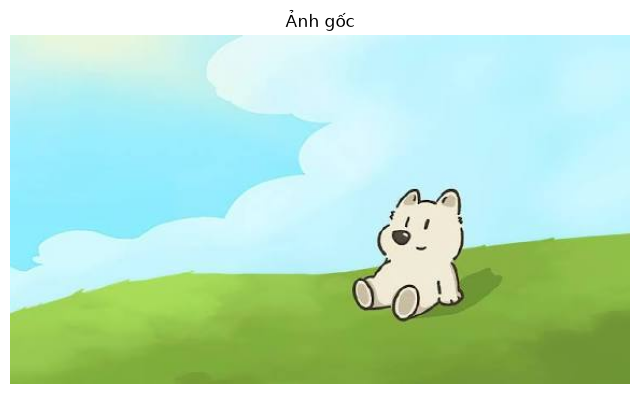

In [2]:
import sys
print("Python venv:", sys.executable)

import cv2
import numpy as np
import matplotlib.pyplot as plt

img_path = r"C:\Users\asus\Downloads\anhne.jpg"
# Đọc ảnh Unicode an toàn trên Windows; đổi img_path nếu cần
img = cv2.imdecode(np.fromfile(img_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if img is None:
    # Tìm ảnh đầu vào trong thư mục dự án nếu đường dẫn mẫu không tồn tại
    candidates = list(__import__('pathlib').Path('.').glob('*.jpg')) + list(__import__('pathlib').Path('.').glob('*.png'))
    candidates = [x for x in candidates if not x.name.startswith(('I1_', 'I2_', 'I3_', 'I4_'))]
    if candidates:
        img_path = str(candidates[0])
        img = cv2.imdecode(np.fromfile(img_path, dtype=np.uint8), cv2.IMREAD_COLOR)
assert img is not None, "Không đọc được ảnh. Hãy sửa img_path thành đường dẫn ảnh hợp lệ."

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray    = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print("✅ Kích thước:", img.shape)

plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title("Ảnh gốc")
plt.axis("off")
plt.show()

PHẦN I: Toán Tử Điểm Ảnh

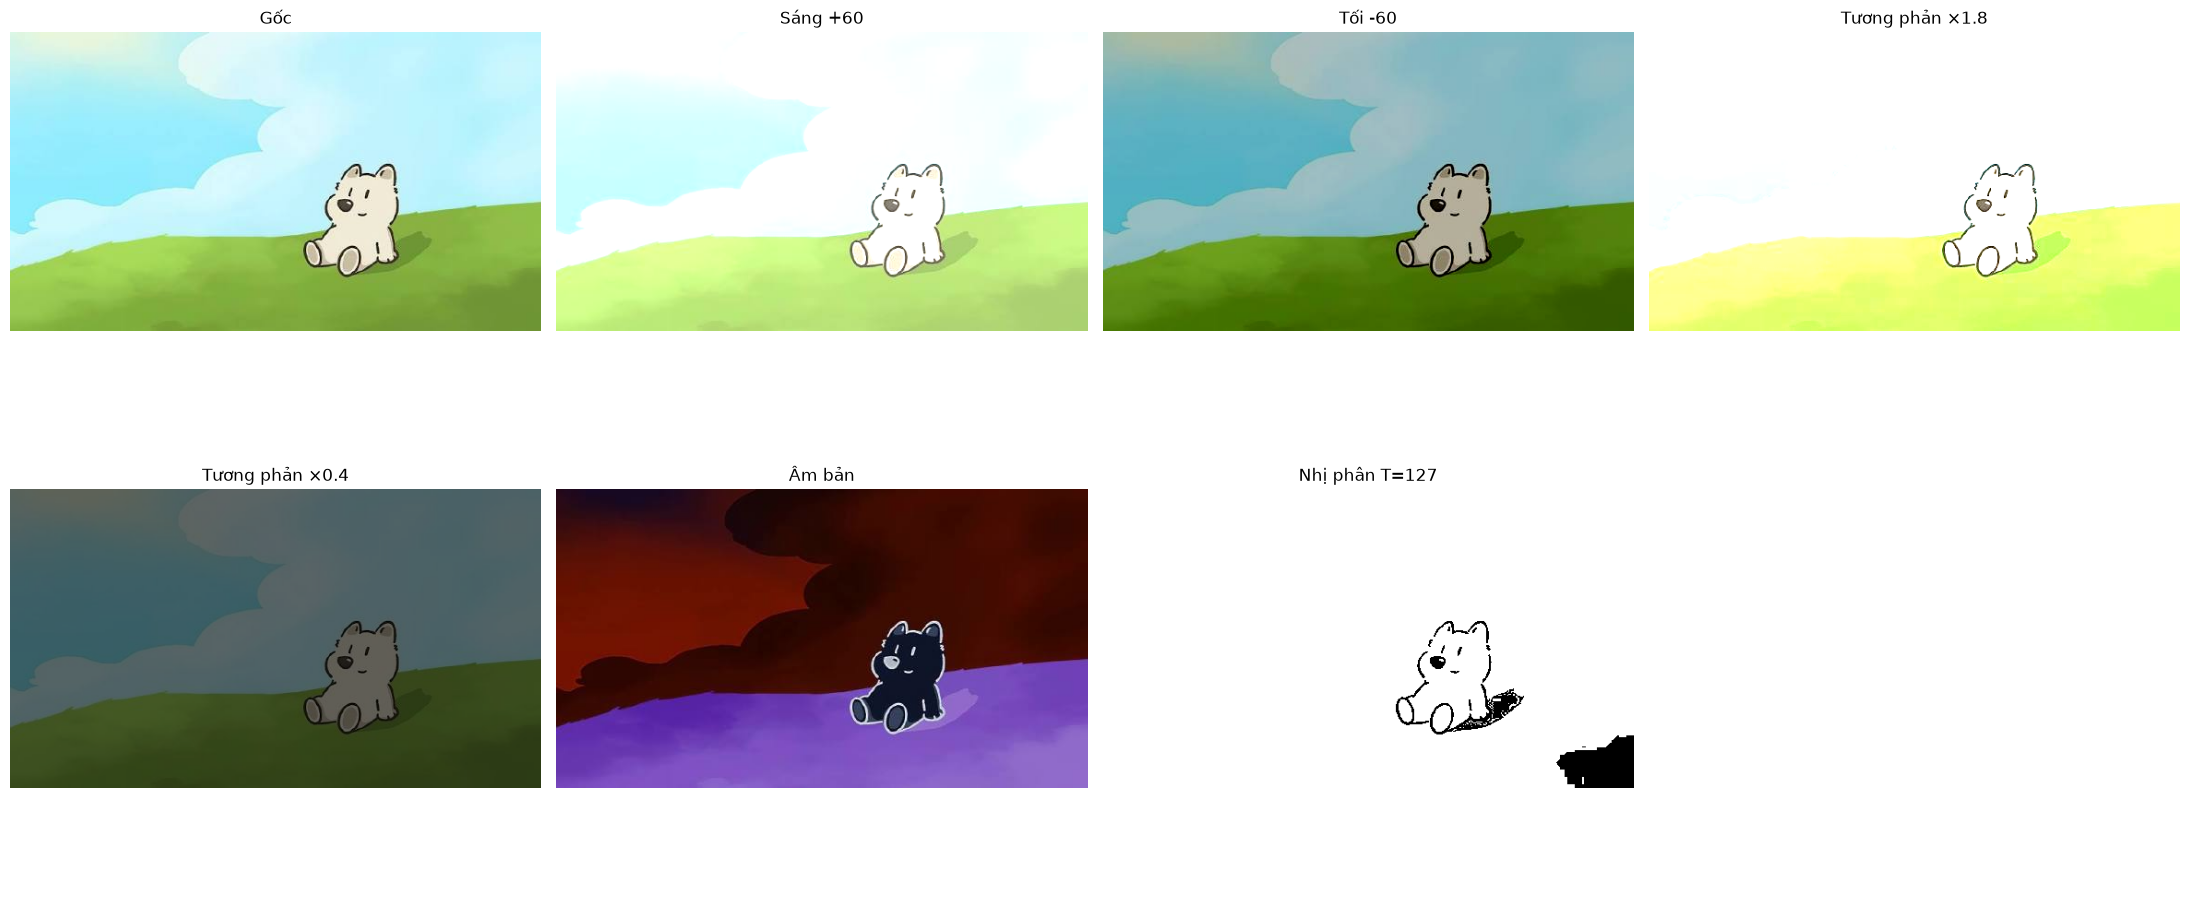

✅ Đã lưu 6 ảnh phần I


In [5]:

# I. TOÁN TỬ ĐIỂM ẢNH

# 1. Thay đổi độ sáng (cộng/trừ hằng số)
bright_up   = cv2.add(img, np.full(img.shape, 60, dtype=np.uint8))       # +60
bright_down = cv2.subtract(img, np.full(img.shape, 60, dtype=np.uint8))  # -60

# 2. Thay đổi độ tương phản (nhân hằng số)
contrast_up   = cv2.convertScaleAbs(img, alpha=1.8, beta=0)   # tăng
contrast_down = cv2.convertScaleAbs(img, alpha=0.4, beta=0)   # giảm

# 3. Biến đổi âm bản
negative = 255 - img

# 4. Cắt ngưỡng → nhị phân
_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# Hiển thị kết quả
fig, axes = plt.subplots(2, 4, figsize=(22, 10))

items = [
    (img_rgb,                                          "Gốc",              None),
    (cv2.cvtColor(bright_up,   cv2.COLOR_BGR2RGB),    "Sáng +60",         None),
    (cv2.cvtColor(bright_down, cv2.COLOR_BGR2RGB),    "Tối -60",          None),
    (cv2.cvtColor(contrast_up, cv2.COLOR_BGR2RGB),    "Tương phản ×1.8",  None),
    (cv2.cvtColor(contrast_down, cv2.COLOR_BGR2RGB),  "Tương phản ×0.4",  None),
    (cv2.cvtColor(negative,    cv2.COLOR_BGR2RGB),    "Âm bản",           None),
    (binary,                                           "Nhị phân T=127",   "gray"),
    (None,                                             "",                 None),
]

for ax, (im, title, cm) in zip(axes.flat, items):
    if im is not None:
        ax.imshow(im, cmap=cm)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Lưu ảnh
cv2.imwrite("I1_bright_up.jpg",     bright_up)
cv2.imwrite("I1_bright_down.jpg",   bright_down)
cv2.imwrite("I2_contrast_up.jpg",   contrast_up)
cv2.imwrite("I2_contrast_down.jpg", contrast_down)
cv2.imwrite("I3_negative.jpg",      negative)
cv2.imwrite("I4_binary.jpg",        binary)
print("✅ Đã lưu 6 ảnh phần I")

## II–III: Lọc tuyến tính và bài tập nâng cao


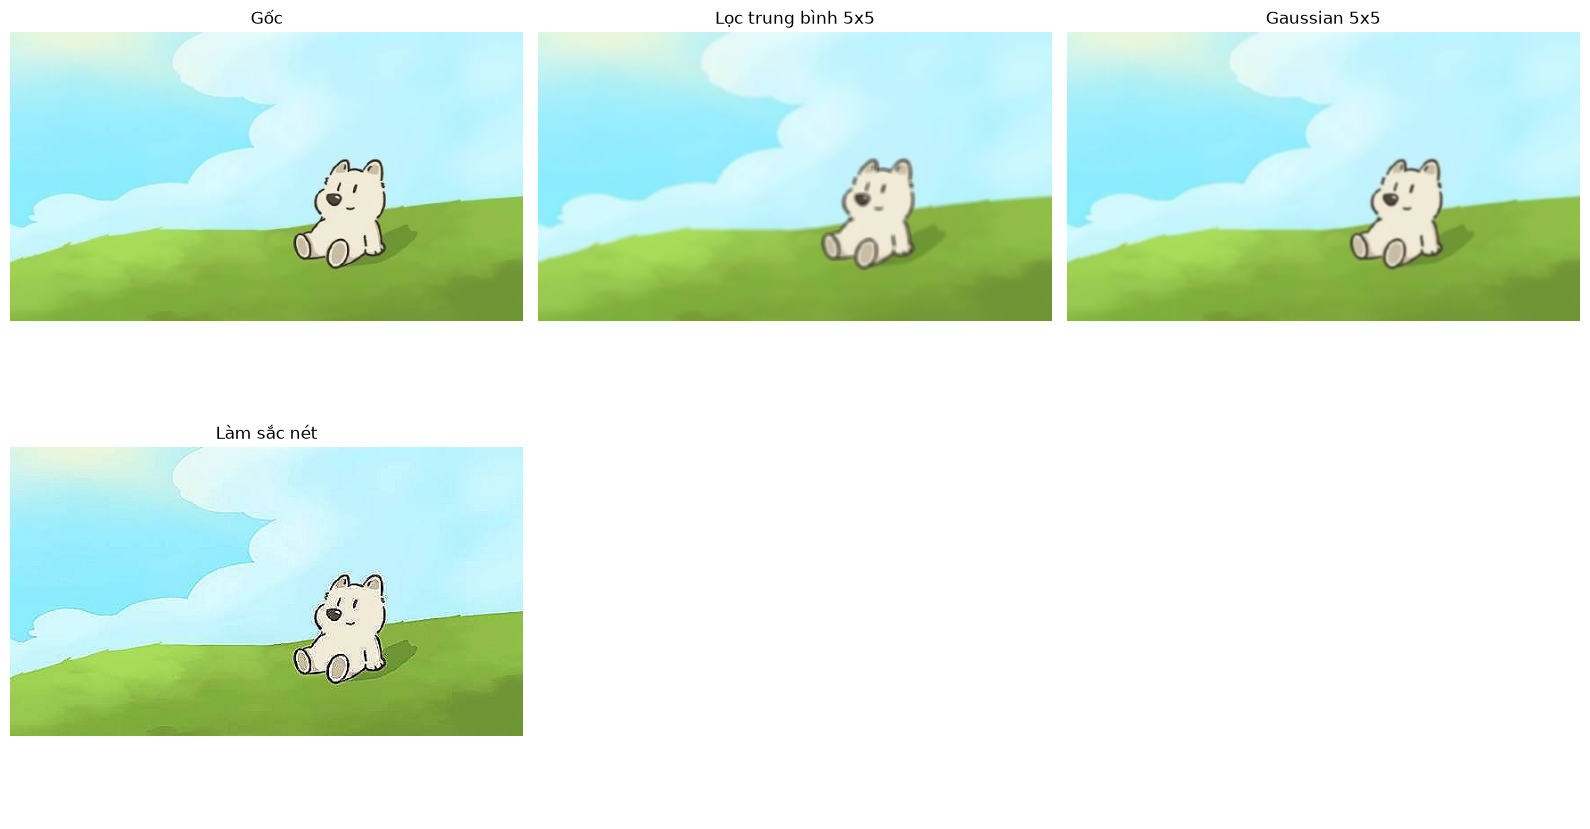

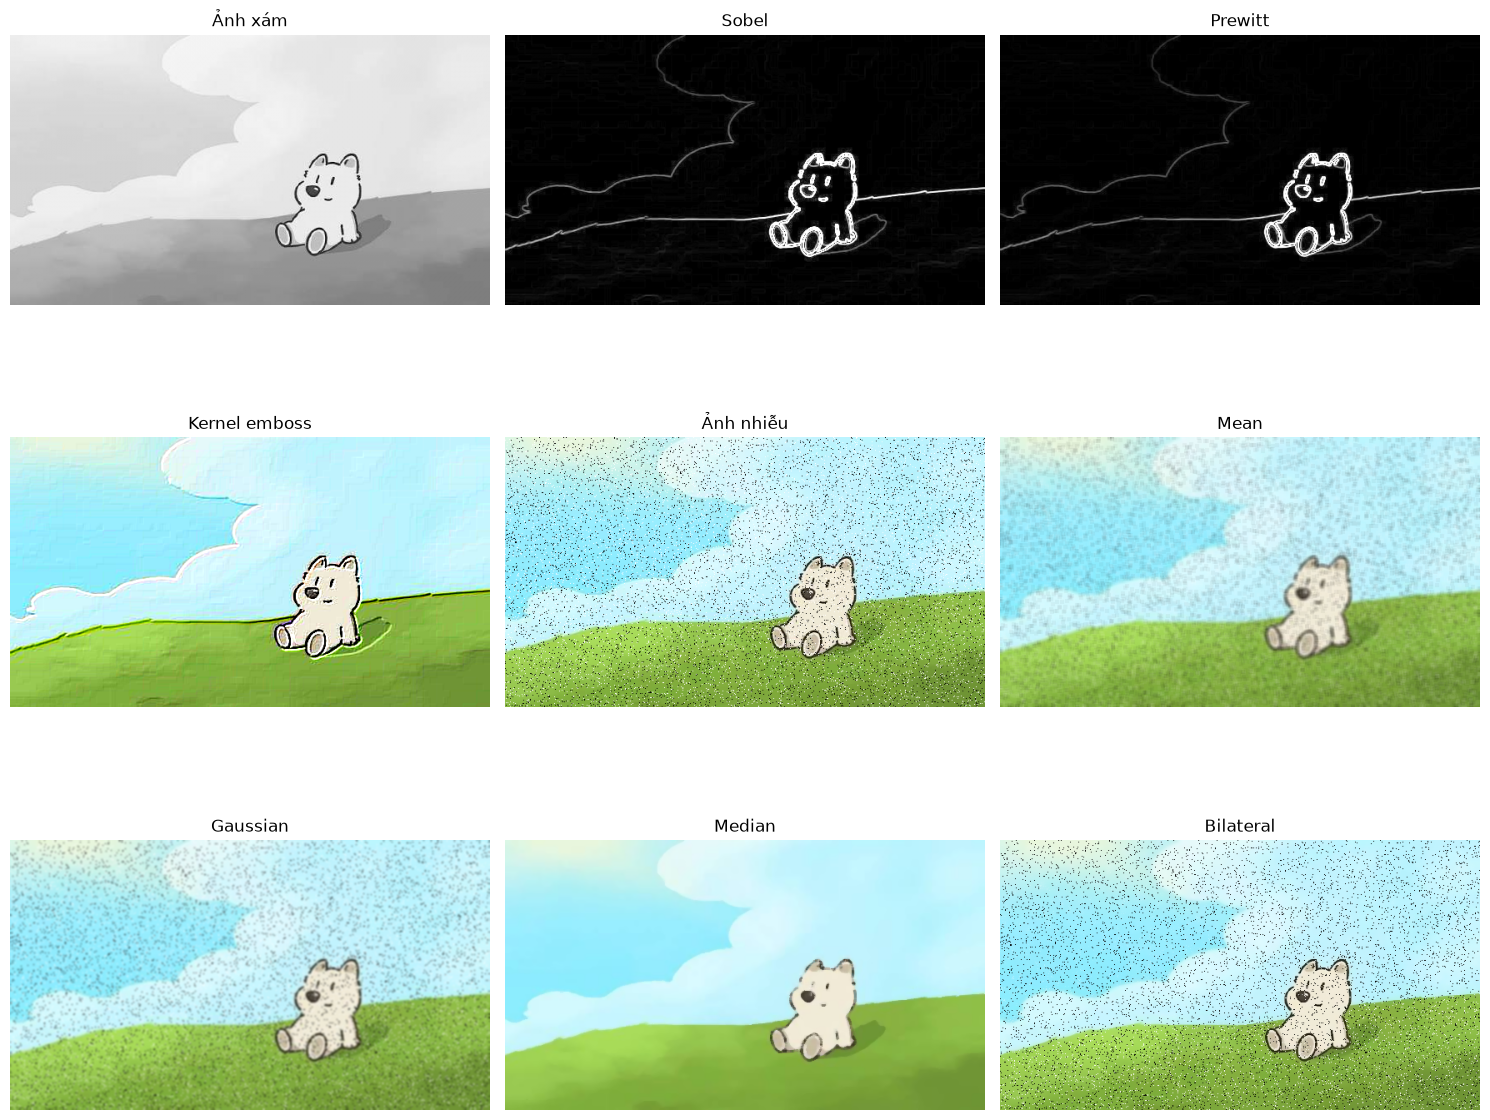

PSNR (dB) trên ảnh nhiễu:
  Mean     : 25.19
  Gaussian : 24.98
  Median   : 30.48
  Bilateral: 15.45


In [4]:
## II. LỌC TUYẾN TÍNH

# Lọc trung bình và Gaussian
mean_blur = cv2.blur(img, (5, 5))
gaussian_blur = cv2.GaussianBlur(img, (5, 5), sigmaX=1.2)

# Làm sắc nét bằng kernel Laplacian (unsharp mask)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
sharpened = cv2.filter2D(img, -1, sharpen_kernel)

def show_bgr_grid(items, cols=3, figsize=(16, 9)):
    rows = int(np.ceil(len(items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, (image, title, cmap) in zip(axes, items):
        ax.imshow(image if cmap else cv2.cvtColor(image, cv2.COLOR_BGR2RGB), cmap=cmap)
        ax.set_title(title); ax.axis("off")
    for ax in axes[len(items):]: ax.axis("off")
    plt.tight_layout(); plt.show()

show_bgr_grid([(img, "Gốc", None), (mean_blur, "Lọc trung bình 5x5", None),
               (gaussian_blur, "Gaussian 5x5", None), (sharpened, "Làm sắc nét", None)])
cv2.imwrite("II_mean.jpg", mean_blur); cv2.imwrite("II_gaussian.jpg", gaussian_blur); cv2.imwrite("II_sharpened.jpg", sharpened)

## III. BÀI TẬP NÂNG CAO

# 1. Sobel và Prewitt trên ảnh xám
gray_f = gray.astype(np.float32)
sobel_x = cv2.Sobel(gray_f, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_f, cv2.CV_32F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sobel_x, sobel_y))
prewitt_x_kernel = np.array([[-1,0,1],[-1,0,1],[-1,0,1]], np.float32)
prewitt_y_kernel = np.array([[-1,-1,-1],[0,0,0],[1,1,1]], np.float32)
prewitt_x = cv2.filter2D(gray_f, cv2.CV_32F, prewitt_x_kernel)
prewitt_y = cv2.filter2D(gray_f, cv2.CV_32F, prewitt_y_kernel)
prewitt = cv2.convertScaleAbs(cv2.magnitude(prewitt_x, prewitt_y))

# 2. Kernel tự thiết kế: emboss
emboss_kernel = np.array([[-2,-1,0],[-1,1,1],[0,1,2]], np.float32)
emboss = cv2.filter2D(img, -1, emboss_kernel)

# 3. So sánh các bộ lọc trên ảnh nhiễu muối tiêu
rng = np.random.default_rng(42)
noisy = img.copy()
mask = rng.random(gray.shape) < 0.04
noisy[mask] = 255
mask = rng.random(gray.shape) < 0.04
noisy[mask] = 0
noisy_mean = cv2.blur(noisy, (5,5))
noisy_gaussian = cv2.GaussianBlur(noisy, (5,5), 1.2)
noisy_median = cv2.medianBlur(noisy, 5)
noisy_bilateral = cv2.bilateralFilter(noisy, 9, 75, 75)

show_bgr_grid([(gray, "Ảnh xám", "gray"), (sobel, "Sobel", "gray"), (prewitt, "Prewitt", "gray"),
               (emboss, "Kernel emboss", None), (noisy, "Ảnh nhiễu", None), (noisy_mean, "Mean", None),
               (noisy_gaussian, "Gaussian", None), (noisy_median, "Median", None), (noisy_bilateral, "Bilateral", None)], cols=3, figsize=(15, 13))
for name, image in [("III_sobel",sobel),("III_prewitt",prewitt),("III_emboss",emboss),("III_noisy",noisy),("III_mean_noisy",noisy_mean),("III_gaussian_noisy",noisy_gaussian),("III_median",noisy_median),("III_bilateral",noisy_bilateral)]:
    cv2.imwrite(name + ".jpg", image)

# Định lượng so sánh: MSE/PSNR với ảnh gốc (giá trị cao hơn tốt hơn)
def psnr(reference, result):
    mse = np.mean((reference.astype(np.float32)-result.astype(np.float32))**2)
    return float("inf") if mse == 0 else float(10*np.log10(255**2/mse))
print("PSNR (dB) trên ảnh nhiễu:")
for name, image in [("Mean",noisy_mean),("Gaussian",noisy_gaussian),("Median",noisy_median),("Bilateral",noisy_bilateral)]:
    print(f"  {name:9s}: {psnr(img, image):.2f}")
